In [ ]:
import polars as pl
from datetime import date, timedelta
import yaml
import json
import matplotlib.pyplot as plt
import dayplot as dp


def daterange(start_date: date, end_date: date):
    days = (end_date - start_date).days
    for n in range(days):
        yield start_date + timedelta(n)


with open("../config.yaml", "r") as fp:
    config = yaml.safe_load(fp)

In [2]:
data = pl.read_csv(
    config["dirs"]["pickwell"] + "/2023/10/01/location-82840-part0000.csv.gz",
    separator="\t",
    schema_overrides={"altitude_accuracy": pl.Float64, "OS_version": pl.String},
)

In [3]:
data

timestamp,device_aid_hashed,device_aid_type,latitude,longitude,horizontal_accuracy,altitude,altitude_accuracy,location_method,ip,OS,OS_version,manufacturer,model,carrier
i64,str,str,f64,f64,f64,f64,f64,str,str,str,str,str,str,str
1696165200,"""17d6021bd57f46018332cba788e055…","""AAID""",47.66252,19.075834,17.0,110.7,0.0,"""gps""","""37.76.18.72""","""Android""",null,null,null,null
1696165200,"""966616f55faeff2574c612f8b09fb3…","""AAID""",47.375797,18.739253,14.1,0.0,0.0,"""gps""",null,"""Android""",null,null,null,null
1696165200,"""20a73d150f3178f5520ac6e94d5316…","""AAID""",47.343186,19.031103,16.3,148.7,3.6,"""fused""","""84.225.162.61""","""Android""",null,null,null,null
1696165200,"""0282363d11828091d5bd44eb0db659…","""AAID""",46.903772,19.684479,6.2,160.3,0.0,"""fused""",null,"""Android""","""10.0.0""","""HUAWEI""",null,null
1696165200,"""aab871add27857f8659df66193d012…","""AAID""",47.385432,19.21855,6.0,0.0,0.0,"""gps""",null,"""Android""",null,"""Samsung""","""SM-A505FN""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1696161599,"""9d8d596c0d16b134b1df851bd28bab…","""AAID""",47.408692,19.06693,7.2,143.4,0.0,"""fused""",null,"""Android""",null,null,null,null
1696161599,"""49c9fefa55858484d19fede37d097a…","""AAID""",47.436393,19.217544,64.0,132.8,0.0,"""gps""","""188.156.116.175""","""Android""","""11""","""XIAOMI""",null,null
1696161599,"""1440f19cb9d61d26dbf341b79b4f6c…","""AAID""",47.910683,19.886721,12.8,814.0,0.0,"""fused""",null,"""Android""",null,null,null,null


In [4]:
len(data["device_aid_hashed"].unique())

41560

In [5]:
def determine_descriptives(d: date) -> dict[str, int]:
    result = {}
    data = pl.read_csv(
        config["dirs"]["pickwell"]
        + "/"
        + d.strftime("%Y/%m/%d")
        + "/location-82840-part0000.csv.gz",
        separator="\t",
        quote_char=None,
        schema_overrides={"altitude_accuracy": pl.Float64, "OS_version": pl.String},
    )
    result["number_of_records"] = len(data)
    result["number_of_unique_devices"] = len(data["device_aid_hashed"].unique())
    return result

In [6]:
try:
    with open("../output/descriptives/counts_2023.json", "r") as fp:
        counts_2023 = json.load(fp)
except FileNotFoundError:
    # runs 3 minutes for 2023-10-01--2023-12-31
    counts_2023 = {}
    for i in daterange(date(2023, 10, 1), date(2023, 12, 31)):
        counts_2023[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open("../output/descriptives/counts_2023.json", "w") as fp:
        json.dump(counts_2023, fp, indent=1)


In [7]:
try:
    with open("../output/descriptives/counts_2024.json", "r") as fp:
        counts_2024 = json.load(fp)
except FileNotFoundError:
    # runs 5 minutes
    counts_2024 = {}
    for i in daterange(date(2024, 1, 1), date(2024, 2, 29)):
        counts_2024[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    for i in daterange(date(2024, 10, 1), date(2024, 12, 31)):
        counts_2024[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open("../output/descriptives/counts_2024.json", "w") as fp:
        json.dump(counts_2024, fp, indent=1)


In [8]:
try:
    with open("../output/descriptives/counts_2025.json", "r") as fp:
        counts_2025 = json.load(fp)
except FileNotFoundError:
    counts_2025 = {}
    for i in daterange(date(2025, 1, 1), date(2025, 12, 31)):
        counts_2025[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open("../output/descriptives/counts_2025.json", "w") as fp:
        json.dump(counts_2025, fp, indent=1)

In [31]:
def counts_to_dataframe(counts: dict[str, dict[str, int]]) -> pl.DataFrame:
    records = []
    for k, v in counts.items():
        records.append(
            [
                date(*map(int, k.split("-"))),
                v["number_of_records"],
                v["number_of_unique_devices"],
            ]
        )
    return pl.from_records(
        records,
        schema=["day", "number_of_records", "number_of_unique_devices"],
        orient="row",
    )

In [34]:
cdf_23 = counts_to_dataframe(counts_2023)
cdf_24 = counts_to_dataframe(counts_2024)
cdf_25 = counts_to_dataframe(counts_2025)

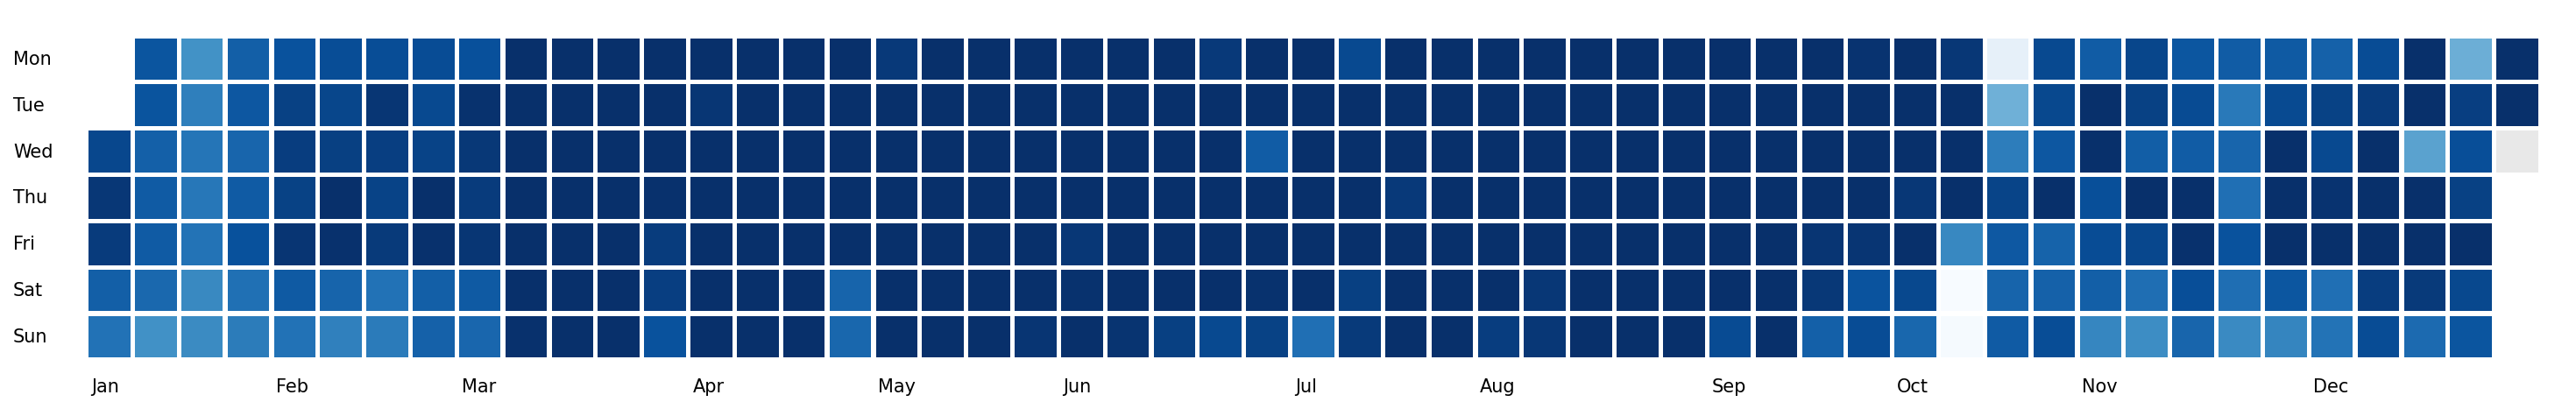

In [ ]:
fig, ax = plt.subplots(figsize=(30, 3), dpi=150, layout="constrained")
_ = dp.calendar(
    dates=cdf_25["day"],
    values=cdf_25["number_of_records"],
    start_date="2025-01-01",
    end_date="2025-12-31",
    week_starts_on="Monday",
    ax=ax,
    cmap="Blues",
)


# for i in ["png", "svg"]:
#     fig.savefig(
#         f"../output/descriptives/number_of_records.{i}",
#         metadata=config["metadata"][i],
#     )